In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, LeaveOneGroupOut

In [2]:
SEED = 42
np.random.seed(SEED)

# folder containing 'Person A' ... 'Person F'
DATA_ROOT = Path("data")

# folder for report figures
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# file names: g1=wave, g2=pinch, g3=swipe, g4=click
GESTURES = ["wave", "pinch", "swipe", "click"]

# Load data

In [3]:
# Find all CSV files
paths = DATA_ROOT.glob("Person */*/*.csv")

# Loop over files
spectrograms, metadata_list = [], []
for path in paths:
    # Extract the person and gesture from the filename
    person, gesture = re.search(r"Person([A-Z])g(\d)s\d+\.csv$", path.name).groups()

    # Read the data (CSVs have no header row)
    x = pd.read_csv(path, header=None).to_numpy()
    spectrograms.append(x)

    # Store the info about the sample
    gesture_index = int(gesture) - 1
    metadata_list.append({
        "person": person,
        "label": gesture_index,
        "gesture": GESTURES[gesture_index]
    })

# Convert the meta info to a dataframe
metadata = pd.DataFrame(metadata_list)

In [4]:
# Show the data
print(f'Loaded {len(spectrograms)} spectrograms')
display(metadata.groupby(["person", "gesture"]).size().unstack())

Loaded 960 spectrograms


gesture,click,pinch,swipe,wave
person,,,,
A,40,40,40,40
B,40,40,40,40
C,40,40,40,40
D,40,40,40,40
E,40,40,40,40
F,40,40,40,40


# Data Exploration

In [5]:
# Check for missing (NaN) and infinite values
n_nan = sum(np.isnan(x).any() for x in spectrograms)
n_inf = sum(np.isinf(x).any() for x in spectrograms)

print(f"Samples with NaN: {n_nan}")
print(f"Samples with inf: {n_inf}")

Samples with NaN: 0
Samples with inf: 0


### Data shape
```spectograms``` is a list of N arrays
- each array represents one spectogram
- rows = Doppler bins (800 bins for each sample)
- cols = time bins (varying number of bins depending on gesture duration)
- values = magnitudes in dB

```metadata``` is a dataframe with one row per sample
each row contains the person and gesture

The ```metadata``` dataframe and ```spectograms``` list are aligned

In [6]:
# Shape of the data
n_doppler = np.unique([x.shape[0] for x in spectrograms])
n_time = np.array([x.shape[1] for x in spectrograms])

print(f"Doppler bins (rows):  {n_doppler}")
print(f"Time bins (columns):  min {n_time.min()}, max {n_time.max()}")
print(f"Value range [dB]:     min {min(x.min() for x in spectrograms):.1f}, max {max(x.max() for x in spectrograms):.1f}")
print(f"Example sample:       A spectrogram of shape {spectrograms[0].shape} -> {metadata.iloc[0].to_dict()}")

Doppler bins (rows):  [800]
Time bins (columns):  min 43, max 448
Value range [dB]:     min -121.3, max 0.0
Example sample:       A spectrogram of shape (800, 92) -> {'person': 'A', 'label': 3, 'gesture': 'click'}


**Interpretation:** 
- The spectograms in the dataset all have a fixed number of 800 doppler bins. 
- The number of time bins varies between a minimum of 43 and a maximum of 448 depending on the sample and the gesture.
- The magnitude values are normalized to their own maximum, so the max value is 0 dB.

### Example plots

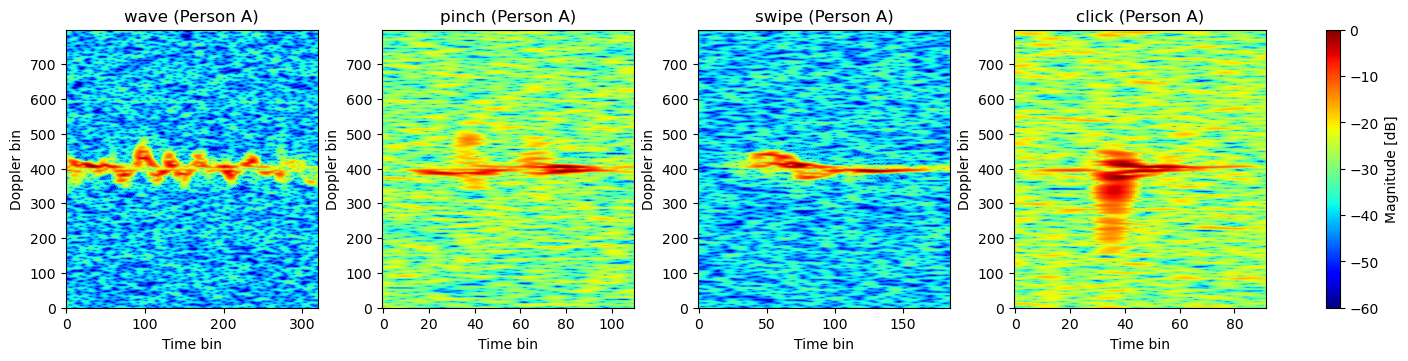

In [7]:
# Create four subplots
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), constrained_layout=True)

# Loop over the gestures
for ax, g in zip(axes, GESTURES):
    i = metadata.index[metadata.gesture == g][0]

    # Show spectogram as image
    im = ax.imshow(spectrograms[i], aspect="auto", origin="lower", cmap="jet", vmin=-60, vmax=0)

    # Set title and labels
    ax.set_title(f"{g} (Person {metadata.person[i]})")
    ax.set_xlabel("Time bin")
    ax.set_ylabel("Doppler bin")

# Add a colorbar
fig.colorbar(im, ax=axes, label="Magnitude [dB]")

# Save the figure as pdf
fig.savefig(FIG_DIR / "spectrograms.pdf", bbox_inches="tight")
plt.show()

# Data split
The dataset is split into three roles: training, validation and test.

- The test set (20%) is separated first before any data (pre-)processing happens. This prevents data leakage from the test set into the training data. The test set is only used at the very end to evaluate the model performance. The split is stratified on person and gesture so every person-gesture combination has the same share in the test set.
- The training set (80%) contains the remaining data.
- Validation will be done with stratified 5-fold cross-validation. The training set is split into 5 folds, stratified on person and gesture (like the test split), so every fold has the same share of each person-gesture combination. The persons differ a lot (e.g. Person B's samples are much noisier), so this keeps the folds comparable and the fold-to-fold spread of the score honest. We train the model on 4 of the 5 folds and then evaluate its performance using the remaining 5th fold. This is repeated for every fold, so that each fold acts as test fold exactly once. The model and hyperparameters will be chosen based on the mean validation score over the folds. This way, no data is lost to validation and this provides a more reliable method than a single small validation set.

After picking the model and hyperparameters using the K-folds cross-validation, the model is retrained on the entire training set. Since this retraining now uses the data that was first used for validation (which influened the model choice). So the model is then tested on the test set that was set aside at the very beginning, which presents data the model has never seen before.

Additionally, it is interesting to see how well the model generalizes to new people. Therefore, additional validation is done by leaving one person out per fold. Since there are 6 persons (A through F), that means there will be 6 folds. This provides additional insight into the model performance.

So
1. Separate a 20% test set
2. Choose model and hyperparameters based on 5-fold cross-validation
3. Retrain the chosen model using the 6-fold LOSO (leave-one-subject-out) and report performance
4. Retrain the chosen model on all training data. This gives the final model
5. Evaluate the final model using the test set from the beginning.



In [8]:
# Extract the labels (gestures)
labels = metadata.label.to_numpy()

# Extract the persons
persons = metadata.person.to_numpy()

# Person-gesture combination of each sample, used for stratifying
strata = (metadata.person + "_" + metadata.gesture).to_numpy()

# Separate a test set
# Stratify on person and gesture
idx_train, idx_test = train_test_split(
    np.arange(len(metadata)),
    test_size=0.2,
    stratify=strata,
    random_state=SEED,
)

# Create the K-fold splits of the training data, also stratified on person and gesture
# Returns [(train1_idx, val1_idx), ..., (train5_idx, val5_idx)]
# Note: these are positions within idx_train, so use idx_train[train1_idx] to get sample indices
kfold = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(idx_train, strata[idx_train]))

# Create the LOSO folds (also positions within idx_train)
loso = list(LeaveOneGroupOut().split(idx_train, labels[idx_train], persons[idx_train]))

In [9]:
# Print the number of samples per set and the number of generated folds
print(f"Train:        {len(idx_train)}")
print(f"Test:         {len(idx_test)}")
print(f"k-fold folds: {len(kfold)}")
print(f"LOSO folds:   {len(loso)}")

# Show the split (this shows the stratifying worked)
split = np.where(
    np.isin(np.arange(len(metadata)), idx_test), 
    "test", 
    "train"
)
display(metadata.groupby([split, "gesture"]).size().unstack())

Train:        768
Test:         192
k-fold folds: 5
LOSO folds:   6


gesture,click,pinch,swipe,wave
test,48,48,48,48
train,192,192,192,192


# Data pre-processing

Every spectrogram is pre-processed **by itself**, using only that sample and fixed constants, so the function can be applied to all 960 samples (training and test) without leaking test information. The constants were chosen on the training samples only; the analysis and figures behind them are in `preprocessing.ipynb`.

1. **Doppler crop to bins 140–660:** the smallest window around zero Doppler (bin 400) that keeps ≥ 99% of the gesture energy in *every* training sample. Outside it there is only background noise.
2. **Noise floor per sample:** the background noise level differs a lot between recordings (about −55 to −17 dB, due to distance to the radar, the size of the moving body part and the recording conditions), and says nothing about the gesture. Each sample is therefore clipped at its *own* floor $f = \mu + 8$ dB, with $\mu$ the median of its Doppler bins outside the crop window (pure noise). The 8 dB margin removes about 99% of the noise while keeping practically all gesture energy.
3. **Scaling to [0, 1]:** $X = (\max(S, f) - f) / (0 - f)$, so the noise floor becomes 0 and the peak (0 dB) becomes 1.
4. **Resize to 128 × 128** (Doppler × time) by linear interpolation: keeps every gesture complete; the lost duration mostly tells *who* made the gesture, not *which* gesture.

In [10]:
from scipy.ndimage import zoom

# Pre-processing constants, chosen in preprocessing.ipynb on the training samples only
DOPPLER_CROP = (140, 660)  # 1. keep Doppler bins 140-659 around zero Doppler (bin 400)
NOISE_FLOOR_MARGIN = 8     # 2. floor = sample's own noise level + 8 dB
OUT_SHAPE = (128, 128)     # 4. (Doppler, time) input size

def preprocess(x, crop=DOPPLER_CROP, margin=NOISE_FLOOR_MARGIN, out_shape=OUT_SHAPE):
    """Pre-process one spectrogram: Doppler crop, per-sample noise floor, scale to [0, 1], resize."""
    # Noise floor of this sample: median of the bins outside the crop window (pure noise) plus a margin
    floor = np.median(np.concatenate([x[:crop[0]], x[crop[1]:]])) + margin

    # 1. Doppler crop
    x = x[crop[0]:crop[1]]

    # 2. Clip at the sample's own noise floor
    x = np.maximum(x, floor)

    # 3. Scale [floor, 0] dB to [0, 1]
    x = (x - floor) / (0 - floor)

    # 4. Resize to a fixed shape
    x = zoom(x, (out_shape[0] / x.shape[0], out_shape[1] / x.shape[1]), order=1)

    return x.astype(np.float32)

# Pre-process all samples
# Per-sample operation with fixed constants, so this does not leak test information
X_img = np.stack([preprocess(x) for x in spectrograms])

print(f"X_img: {X_img.shape}, values from {X_img.min():.2f} to {X_img.max():.2f}")

X_img: (960, 128, 128), values from 0.00 to 1.00


# Feature engineering
The models get their input from the pre-processed spectrograms. Two kinds of feature sets are compared:

**Image features** (from the pre-processed 128 × 128 images, `X_img`):
1. **Flattened spectrogram:** all 128 × 128 = 16 384 pixel values, standardised per pixel (zero mean, unit variance).
2. **PCA:** the 50 principal components of the flattened spectrogram, standardised. There are far more pixels (16 384) than training samples (768), so PCA keeps only the 50 directions with the most variance; this reduces overfitting and speeds up training.

**Hand-crafted features** from the three papers suggested in the project description: spectrogram envelopes (Amin et al., 2019), Doppler centroid and bandwidth (Fioranelli et al., 2016) and Chebyshev moments (Pallotta et al., 2021). These describe the *motion* (how fast the hand moves, how wide the velocity spread is, how it changes over time) with far fewer numbers than the pixels.

The standardisation and PCA are defined as pipeline steps, not applied to the data directly: in the models section they are put in one `Pipeline` with the classifier, so they are fitted **only on the training part of each fold** and never see the validation or test samples. The hand-crafted features are computed per sample with fixed formulas, so they can be computed for all samples at once without leakage.

In [11]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Image features: flatten the pre-processed images, one row of 128 * 128 pixels per sample
X = X_img.reshape(len(X_img), -1)
y_train, y_test = labels[idx_train], labels[idx_test]
train_persons = persons[idx_train]

print(f"Flattened features: {X.shape[1]} per sample ({len(idx_train)} training, {len(idx_test)} test samples)")

Flattened features: 16384 per sample (768 training, 192 test samples)


### Hand-crafted features from the papers
The envelope and centroid features are computed on the **gesture power** at the original time resolution: the Doppler crop (bins 140–660) of the spectrogram, converted to linear power, minus the power of the sample's own noise floor $f$ (from the pre-processing), clipped at 0:

$$P(d, t) = \max\big(10^{S(d,t)/10} - 10^{f/10},\; 0\big)$$

with $d$ the Doppler bin relative to zero Doppler (bin 400) and $t$ the time bin. Linear power is used because the papers weight the Doppler bins by their power; noise below the floor gets weight 0. Time bins whose total power is below 5% of the strongest time bin are skipped: before and after the gesture, a time bin contains only a few noise pixels that survived the floor, and their power-weighted centroid and envelopes jump randomly over the whole Doppler axis.

**1. Envelopes** (Amin et al., 2019). The envelopes follow the outline of the micro-Doppler signature over time: the maximum velocity of the hand towards and away from the radar. Per time bin, the Doppler bin below which a fraction $q$ of the power lies:

$$e_q(t) = \min\Big\{d : \textstyle\sum_{d' \le d} P(d', t) \ge q \sum_{d'} P(d', t)\Big\}$$

with $q = 0.05$ (lower envelope), $0.5$ (central envelope) and $0.95$ (upper envelope). The paper uses the envelope samples themselves as features; because the gestures have different lengths, each envelope is resampled to 16 points over the gesture duration, which gives 3 × 16 = **48 features**.

**2. Doppler centroid and bandwidth** (Fioranelli et al., 2016, Sec. 3.2). The centroid is the power-weighted mean Doppler per time bin (the average velocity of the hand), the bandwidth the power-weighted spread around it (how many different velocities occur at once):

$$f_c(t) = \frac{\sum_d d\, P(d,t)}{\sum_d P(d,t)}, \qquad B(t) = \sqrt{\frac{\sum_d \big(d - f_c(t)\big)^2 P(d,t)}{\sum_d P(d,t)}}$$

As in the paper, the features are statistics of these two curves over time: mean, standard deviation, skewness and kurtosis of $f_c(t)$ and of $B(t)$, which gives **8 features**. They do not depend on the gesture length. (The paper used them for a different task, armed/unarmed personnel, but they describe the velocity profile of any motion.)

**3. Chebyshev moments** (Pallotta et al., 2021). The pre-processed 128 × 128 image $X$ is projected on the orthonormal discrete Chebyshev (Tchebichef) polynomials $t_p$ of degree $p = 0, \dots, 7$ along both axes:

$$T_{pq} = \sum_{d} \sum_{t} t_p(d)\, t_q(t)\, X(d, t), \qquad p, q = 0, \dots, 7$$

Low orders describe the coarse shape of the signature (overall position, spread and tilt in time and Doppler), higher orders finer detail. The 8 × 8 = **64 moments** form a compact, orthogonal description of the image. The polynomials are computed by orthonormalising $1, x, x^2, \dots$ on 128 equally spaced points.

*Note:* the papers are implemented from their published descriptions; the parameters (envelope levels, number of envelope points, moment order) are reasonable first choices and not tuned.

In [12]:
from scipy.stats import skew, kurtosis

DOPPLER = np.arange(*DOPPLER_CROP) - 400  # Doppler bin relative to zero Doppler
ENV_LEVELS = (0.05, 0.5, 0.95)            # lower, central and upper envelope
ENV_POINTS = 16                           # envelope samples per gesture
CHEB_ORDER = 8                            # Chebyshev degrees 0..7 per axis
ACTIVE_FRACTION = 0.05                    # keep time bins with >= 5% of the power of the strongest time bin

def gesture_power(x):
    """P(d, t): linear power above the sample's noise floor inside the Doppler crop window."""
    floor = np.median(np.concatenate([x[:DOPPLER_CROP[0]], x[DOPPLER_CROP[1]:]])) + NOISE_FLOOR_MARGIN
    P = np.maximum(10 ** (x[DOPPLER_CROP[0]:DOPPLER_CROP[1]] / 10) - 10 ** (floor / 10), 0)
    power_per_time = P.sum(axis=0)
    return P[:, power_per_time >= ACTIVE_FRACTION * power_per_time.max()]  # skip time bins with (almost) no gesture

def envelopes(P):
    """Lower, central and upper envelope e_q(t), shape (3, T)."""
    cum = np.cumsum(P, axis=0) / P.sum(axis=0)
    return np.stack([DOPPLER[np.argmax(cum >= q, axis=0)] for q in ENV_LEVELS])

def centroid_bandwidth(P):
    """Doppler centroid f_c(t) and bandwidth B(t)."""
    fc = DOPPLER @ P / P.sum(axis=0)
    bw = np.sqrt(((DOPPLER[:, None] - fc) ** 2 * P).sum(axis=0) / P.sum(axis=0))
    return fc, bw

def chebyshev_basis(n, order=CHEB_ORDER):
    """Orthonormal discrete Chebyshev polynomials t_0..t_{order-1} on n points, as columns."""
    q, _ = np.linalg.qr(np.vander(np.linspace(-1, 1, n), order, increasing=True))
    return q * np.sign(q[-1])  # sign convention: positive at the last point

CHEB = chebyshev_basis(OUT_SHAPE[0])  # the images are square, so the same basis for both axes

def resample(v, n=ENV_POINTS):
    return np.interp(np.linspace(0, 1, n), np.linspace(0, 1, len(v)), v)

def envelope_features(P):
    return np.concatenate([resample(e) for e in envelopes(P)])

def centroid_features(P):
    fc, bw = centroid_bandwidth(P)
    return np.nan_to_num([f(v) for v in (fc, bw) for f in (np.mean, np.std, skew, kurtosis)])

def chebyshev_features(img):
    return (CHEB.T @ img @ CHEB).ravel()

# Compute the hand-crafted features for all samples (per sample, fixed formulas: no leakage)
powers = [gesture_power(x) for x in spectrograms]
F_env = np.stack([envelope_features(P) for P in powers])
F_cent = np.stack([centroid_features(P) for P in powers])
F_cheb = np.stack([chebyshev_features(img) for img in X_img])

# Feature names, for inspection and later feature selection
names_env = [f"env{int(q * 100)}_t{k}" for q in ENV_LEVELS for k in range(ENV_POINTS)]
names_cent = [f"{c}_{s}" for c in ("centroid", "bandwidth") for s in ("mean", "std", "skew", "kurt")]
names_cheb = [f"T{p}{q}" for p in range(CHEB_ORDER) for q in range(CHEB_ORDER)]

print(f"Envelopes:            {F_env.shape[1]} features")
print(f"Centroid + bandwidth: {F_cent.shape[1]} features")
print(f"Chebyshev moments:    {F_cheb.shape[1]} features")
print(f"Shortest gesture after skipping weak time bins: {min(P.shape[1] for P in powers)} time bins")

Envelopes:            48 features
Centroid + bandwidth: 8 features
Chebyshev moments:    64 features
Shortest gesture after skipping weak time bins: 25 time bins


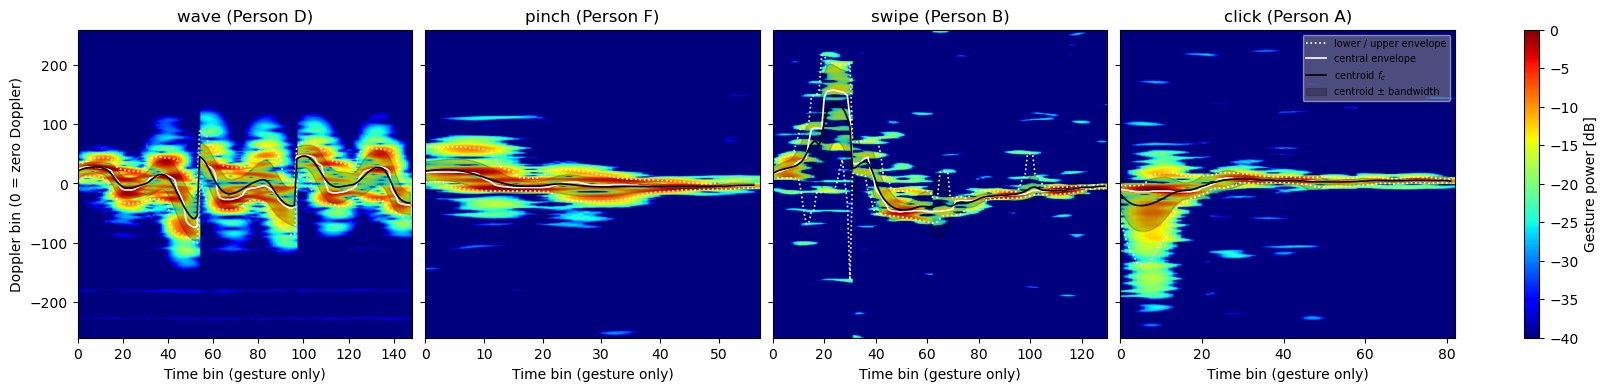

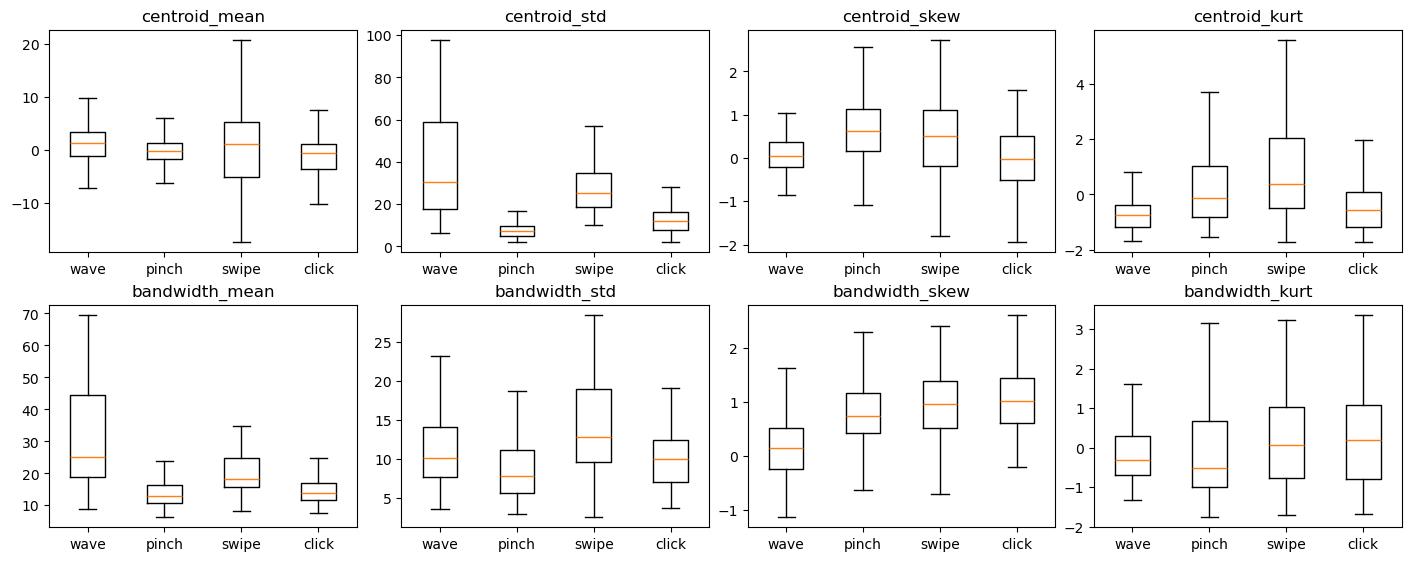

In [13]:
# Envelopes, centroid and bandwidth for one training sample per gesture
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True, constrained_layout=True)
for ax, (k, g) in zip(axes, enumerate(GESTURES)):
    i = idx_train[labels[idx_train] == k][0]
    P = powers[i]
    env = envelopes(P)
    fc, bw = centroid_bandwidth(P)
    t = np.arange(P.shape[1])

    im = ax.imshow(10 * np.log10(np.maximum(P, 1e-6)), aspect="auto", origin="lower", cmap="jet", vmin=-40, vmax=0,
                   extent=[0, P.shape[1], DOPPLER[0], DOPPLER[-1]])
    for e, style, label in zip(env, [":", "-", ":"], ["lower / upper envelope", "central envelope", None]):
        ax.plot(t, e, color="white", linestyle=style, linewidth=1.2, label=label)
    ax.plot(t, fc, color="black", linewidth=1.2, label="centroid $f_c$")
    ax.fill_between(t, fc - bw, fc + bw, color="black", alpha=0.2, label="centroid ± bandwidth")
    ax.set_title(f"{g} (Person {persons[i]})")
    ax.set_ylim(DOPPLER[0], DOPPLER[-1])
    ax.set_xlabel("Time bin (gesture only)")
axes[0].set_ylabel("Doppler bin (0 = zero Doppler)")
axes[-1].legend(fontsize=7, loc="upper right", facecolor="gray", framealpha=0.6)
fig.colorbar(im, ax=axes, label="Gesture power [dB]")
fig.savefig(FIG_DIR / "paper_features.pdf", bbox_inches="tight")
plt.show()

# Distribution of the centroid and bandwidth features per gesture (training set)
train_gestures = np.array(GESTURES)[labels[idx_train]]
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5), constrained_layout=True)
for ax, (j, name) in zip(axes.ravel(), enumerate(names_cent)):
    ax.boxplot([F_cent[idx_train][train_gestures == g, j] for g in GESTURES], showfliers=False)
    ax.set_xticks(range(1, 5), GESTURES)
    ax.set_title(name)
fig.savefig(FIG_DIR / "centroid_features.pdf", bbox_inches="tight")
plt.show()

**Results.**
- **Figure (envelopes, centroid, bandwidth):** the features follow the motion. The wave shows a periodic centroid swinging around zero Doppler with a wide spread; the swipe one strong excursion to high Doppler followed by a slow return; pinch and click stay close to zero Doppler, with click shortly reaching further (the fast finger movement) and then staying flat.
- **Boxplots:** single features separate the gestures only partly. The wave has the largest centroid spread (`centroid_std`) and mean bandwidth, the pinch (a small finger movement) the smallest, and the bandwidth skewness is lower for the wave than for the other gestures; the mean centroid is close to 0 for all gestures (the hand moves towards and away from the radar about equally), so it carries little information. The large overlap between gestures is why the features are combined.
- Skipping weak time bins was essential: without it, the few noise pixels that survive the floor before and after the gesture made the envelopes and centroid jump over the whole Doppler axis (5-fold CV of the random forest on the envelopes: 0.872 without, 0.908 with).

### Feature sets
All feature sets that are compared in the models section. Each is a feature matrix for all 960 samples plus the steps that are fitted inside each fold (standardisation, PCA). The hand-crafted groups are also combined into one set.

In [14]:
# Feature sets: name -> (feature matrix for all samples, steps fitted inside each fold before the classifier)
F_hand = np.hstack([F_env, F_cent, F_cheb])
feature_sets = {
    "flattened": (X, lambda: [StandardScaler()]),
    "PCA (50)": (X, lambda: [PCA(n_components=50, random_state=SEED), StandardScaler()]),
    "envelopes": (F_env, lambda: [StandardScaler()]),
    "centroid": (F_cent, lambda: [StandardScaler()]),
    "Chebyshev": (F_cheb, lambda: [StandardScaler()]),
    "all hand-crafted": (F_hand, lambda: [StandardScaler()]),
}
display(pd.Series({name: F.shape[1] for name, (F, _) in feature_sets.items()}, name="features").to_frame().T)

,flattened,PCA (50),envelopes,centroid,Chebyshev,all hand-crafted
features,16384,16384,48,8,64,120


# Models
Four basic classifiers are trained on each of the feature sets from the feature engineering section. No hyperparameters are tuned yet (default settings); this gives a first comparison and a reference for later models.

**Models.**

| Model | Idea | Settings (defaults, not tuned) |
|---|---|---|
| Logistic regression | Linear decision boundaries | $C = 1$, L2 regularisation |
| k-nearest neighbours | Label of the most similar training samples; no training | $k = 5$, Euclidean distance |
| SVM | Non-linear boundaries with an RBF kernel and maximum margin | $C = 1$, $\gamma$ = `"scale"` |
| Random forest | Many decision trees on random subsets, majority vote | 300 trees |

The feature steps (standardisation, PCA) and the classifier are combined in one `Pipeline`, so they are fitted **only on the training part of each fold** and never see the validation or test samples.

**Evaluation** (as planned in the data split):
1. 5-fold cross-validation on the training set (stratified on person and gesture).
2. Leave-one-subject-out (LOSO) on the training set: how well does the model work for a person it has never seen?
3. Retrain on the whole training set and evaluate once on the test set.

In [15]:
import time
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# Classifiers (default settings)
classifiers = {
    "Logistic regression": lambda: LogisticRegression(max_iter=2000),
    "k-NN (k = 5)": lambda: KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)": lambda: SVC(kernel="rbf", C=1, gamma="scale"),
    "Random forest": lambda: RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
}

def make_model(model, features):
    return make_pipeline(*feature_sets[features][1](), classifiers[model]())

def evaluate(model, features):
    """5-fold CV, LOSO (per person) and test accuracy of one model on one feature set."""
    F = feature_sets[features][0]
    F_train, F_test = F[idx_train], F[idx_test]
    cv = cross_val_score(make_model(model, features), F_train, y_train, cv=kfold)
    pred = cross_val_predict(make_model(model, features), F_train, y_train, cv=loso)
    per_person = {p: (pred[train_persons == p] == y_train[train_persons == p]).mean()
                  for p in sorted(np.unique(train_persons))}
    test = accuracy_score(y_test, make_model(model, features).fit(F_train, y_train).predict(F_test))
    return {"5-fold CV": cv.mean(), "CV std": cv.std(), "LOSO": np.mean(list(per_person.values())),
            **{f"LOSO {p}": a for p, a in per_person.items()}, "test": test}

# Loop over all models and feature sets
rows = {}
for features in feature_sets:
    for model in classifiers:
        start = time.time()
        rows[(model, features)] = evaluate(model, features)
        print(f"{model:20s} {features:16s} done in {time.time() - start:5.1f} s")

results = pd.DataFrame(rows).T
results.index.names = ["model", "features"]
display(results.round(3))

Logistic regression  flattened        done in   7.5 s
k-NN (k = 5)         flattened        done in   4.1 s
SVM (RBF)            flattened        done in  53.3 s
Random forest        flattened        done in  15.8 s
Logistic regression  PCA (50)         done in  15.6 s
k-NN (k = 5)         PCA (50)         done in  15.5 s
SVM (RBF)            PCA (50)         done in  19.9 s
Random forest        PCA (50)         done in  23.9 s
Logistic regression  envelopes        done in   0.3 s
k-NN (k = 5)         envelopes        done in   0.1 s
SVM (RBF)            envelopes        done in   0.5 s
Random forest        envelopes        done in  10.4 s
Logistic regression  centroid         done in   0.1 s
k-NN (k = 5)         centroid         done in   0.1 s
SVM (RBF)            centroid         done in   0.3 s
Random forest        centroid         done in  11.1 s
Logistic regression  Chebyshev        done in   0.4 s
k-NN (k = 5)         Chebyshev        done in   0.1 s
SVM (RBF)            Chebysh

,,5-fold CV,CV std,LOSO,LOSO A,LOSO B,LOSO C,LOSO D,LOSO E,LOSO F,test
model,features,,,,,,,,,,
Logistic regression,flattened,0.881,0.016,0.565,0.367,0.422,0.656,0.742,0.492,0.711,0.833
k-NN (k = 5),flattened,0.805,0.021,0.483,0.266,0.367,0.617,0.750,0.430,0.469,0.844
SVM (RBF),flattened,0.848,0.033,0.564,0.312,0.500,0.688,0.711,0.664,0.508,0.844
Random forest,flattened,0.897,0.016,0.641,0.320,0.656,0.750,0.750,0.672,0.695,0.901
Logistic regression,PCA (50),0.858,0.024,0.536,0.336,0.570,0.641,0.633,0.578,0.461,0.859
k-NN (k = 5),PCA (50),0.855,0.015,0.417,0.305,0.266,0.500,0.430,0.508,0.492,0.875
SVM (RBF),PCA (50),0.928,0.021,0.587,0.367,0.648,0.641,0.648,0.633,0.586,0.932
Random forest,PCA (50),0.932,0.011,0.602,0.430,0.609,0.750,0.594,0.672,0.555,0.922
Logistic regression,envelopes,0.734,0.026,0.505,0.367,0.617,0.469,0.539,0.516,0.523,0.708


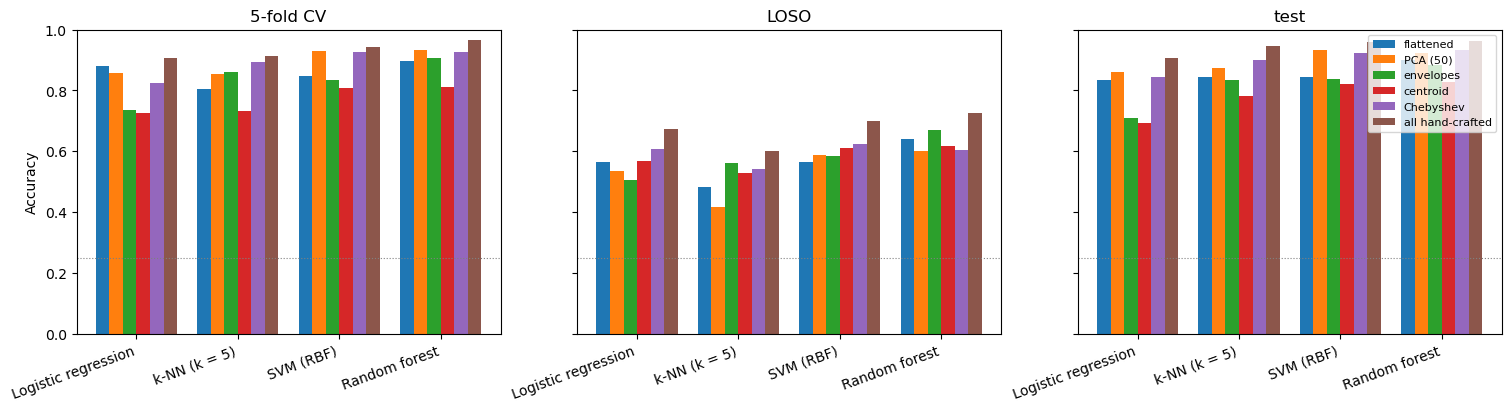

In [16]:
# Accuracy per model and feature set: 5-fold CV, LOSO and test
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True, constrained_layout=True)
width = 0.8 / len(feature_sets)
names = list(classifiers)
pos = np.arange(len(names))
for ax, metric in zip(axes, ["5-fold CV", "LOSO", "test"]):
    for k, features in enumerate(feature_sets):
        values = results.xs(features, level="features").loc[names, metric]
        ax.bar(pos + (k - (len(feature_sets) - 1) / 2) * width, values, width=width, label=features, color=f"C{k}")
    ax.axhline(0.25, color="gray", linestyle=":", linewidth=0.8)  # chance level (4 classes)
    ax.set_xticks(pos, names, rotation=20, ha="right")
    ax.set_title(metric)
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[-1].legend(fontsize=8)
fig.savefig(FIG_DIR / "basic_models.pdf", bbox_inches="tight")
plt.show()

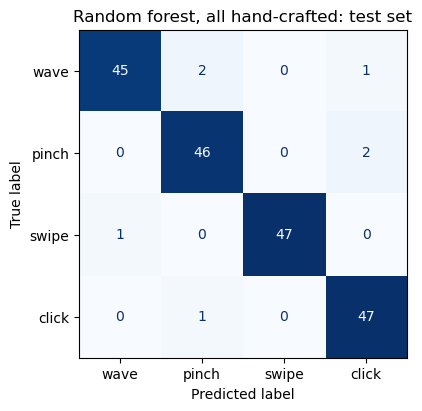

In [17]:
# Confusion matrix on the test set of the best model, chosen on the 5-fold CV accuracy (not on the test set)
best_model, best_features = results["5-fold CV"].idxmax()
F = feature_sets[best_features][0]
y_pred = make_model(best_model, best_features).fit(F[idx_train], y_train).predict(F[idx_test])

fig, ax = plt.subplots(figsize=(4.5, 4), constrained_layout=True)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=GESTURES, cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"{best_model}, {best_features}: test set")
fig.savefig(FIG_DIR / "confusion_best_basic.pdf", bbox_inches="tight")
plt.show()

**Results.** 5-fold CV (mean ± std over the folds), LOSO (mean over the 6 persons) and test accuracy; the best classifier per feature set, plus all classifiers on the combined hand-crafted features:

| Features | # features | Best classifier | 5-fold CV | LOSO | Test |
|---|---|---|---|---|---|
| flattened | 16 384 | Random forest | 0.897 ± 0.016 | 0.641 | 0.901 |
| PCA (50) | 50 | Random forest | 0.932 ± 0.011 | 0.602 | 0.922 |
| envelopes | 48 | Random forest | 0.908 ± 0.010 | 0.669 | 0.885 |
| centroid | 8 | Random forest | 0.810 ± 0.016 | 0.617 | 0.828 |
| Chebyshev | 64 | SVM / random forest | 0.927 | 0.624 / 0.604 | 0.922 / 0.932 |
| **all hand-crafted** | 120 | Logistic regression | 0.906 ± 0.026 | 0.672 | 0.906 |
| | | k-NN | 0.913 ± 0.023 | 0.602 | 0.948 |
| | | SVM (RBF) | 0.943 ± 0.022 | 0.699 | 0.958 |
| | | **Random forest** | **0.967 ± 0.006** | **0.727** | **0.964** |

- **The hand-crafted features beat the pixels.** Combined, the 120 features from the three papers give the best result for every classifier, with far fewer numbers than the 16 384 pixels. The random forest reaches 0.967 on 5-fold CV and 0.964 on the test set (7 errors out of 192).
- **Generalisation to new persons improves most.** LOSO rises from at best 0.641 (pixels) to 0.727 (random forest) and 0.699 (SVM). The envelopes and centroid describe the *motion* (how fast and how widely the hand moves) instead of the exact pixel pattern, which carries over better to a new person. Person A is still the hardest (0.555), Person F the easiest (0.844).
- **The groups complement each other.** No single group comes close to the combination: the envelopes give the motion over time, the centroid statistics a length-independent summary, and the Chebyshev moments the overall shape of the image. The 8 centroid features alone reach only 0.810.
- **Chebyshev moments ≈ PCA:** both are a compact projection of the whole image and perform about the same (≈ 0.93 CV). The Chebyshev basis is fixed instead of fitted, so it does not depend on the training persons.
- **Random forest is the best classifier** on almost every feature set, and the test accuracies stay close to the CV estimates.

Next steps: feature selection on the 120 hand-crafted features (which ones matter, can some be dropped?) and hyperparameter tuning, with the LOSO accuracy as the main target.